### Implementación de un Perceptrón Multi-Salida para Compuertas Lógicas AND y OR

Este código implementará un perceptrón de una sola capa con dos salidas, una para la compuerta AND y otra para la compuerta OR. El perceptrón se entrenará para aprender las funciones de ambas compuertas simultáneamente. Luego, visualizaremos las fronteras de decisión aprendidas para cada una.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definir los datasets para las compuertas AND y OR
# Inputs (X) - Se añade un término de 'bias' (x0=1) para simplificar el manejo de pesos.
X = np.array([
    [1, 0, 0],  # bias, entrada1, entrada2
    [1, 0, 1],
    [1, 1, 0],
    [1, 1, 1]
])

# Targets (Y)
# Columna 0: Salida de la compuerta AND
# Columna 1: Salida de la compuerta OR
y_and = np.array([0, 0, 0, 1])
y_or = np.array([0, 1, 1, 1])
Y = np.column_stack((y_and, y_or))

print("Datos de entrada (X, con bias):\n", X)
print("Datos de salida (Y, [AND, OR]):\n", Y)

Datos de entrada (X, con bias):
 [[1 0 0]
 [1 0 1]
 [1 1 0]
 [1 1 1]]
Datos de salida (Y, [AND, OR]):
 [[0 0]
 [0 1]
 [0 1]
 [1 1]]


### Clase del Perceptrón Multi-Salida

Esta clase implementa un perceptrón que puede tener múltiples neuronas de salida. Cada neurona de salida aprende su propia frontera de decisión. Utiliza la función escalón como función de activación.

In [10]:
class MultiOutputPerceptron:
    def __init__(self, num_inputs, num_outputs, learning_rate=0.1, epochs=100):
        # Inicializar pesos aleatoriamente para evitar simetría inicial
        # self.weights: (num_inputs + 1, num_outputs) porque incluye el bias
        self.weights = np.random.randn(num_inputs + 1, num_outputs) * 0.1 # Pequeños pesos iniciales
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.num_outputs = num_outputs
        self.errors_per_epoch = [] # Añadido para almacenar el error por época

    def activation(self, x):
        # Función de activación escalón (heaviside)
        return np.where(x >= 0, 1, 0)

    def predict(self, inputs):
        # Calcula la salida lineal y aplica la función de activación
        # inputs se espera que ya tenga el término de bias
        linear_output = np.dot(inputs, self.weights)
        return self.activation(linear_output)

    def train(self, X, Y):
        self.errors_per_epoch = [] # Reiniciar la lista de errores al inicio del entrenamiento
        for epoch in range(self.epochs):
            total_error_epoch = 0
            for i in range(X.shape[0]):
                input_vector = X[i]
                target_vector = Y[i]

                # Predicción para todas las neuronas de salida
                # Reshape input_vector para que sea (1, num_inputs+1) para el producto punto
                prediction_vector = self.predict(input_vector.reshape(1, -1)).flatten()

                # Calcular el error para cada neurona de salida
                error_vector = target_vector - prediction_vector

                # Actualizar los pesos para cada neurona de salida
                # delta_weights = learning_rate * (input_vector.T @ error_vector)
                # np.outer(a,b) -> [a_i * b_j]
                delta_weights = self.learning_rate * np.outer(input_vector, error_vector)
                self.weights += delta_weights
                total_error_epoch += np.sum(np.abs(error_vector))
            self.errors_per_epoch.append(total_error_epoch) # Almacenar el error total de la época

            # Si no hay errores, el modelo ha convergido
            if total_error_epoch == 0:
                print(f"El modelo ha convergido en la época {epoch + 1}/{self.epochs}")
                break
        print(f"Entrenamiento finalizado después de {epoch + 1} épocas.")

    def get_decision_boundary_params(self, output_idx):
        # Para una neurona de salida, la frontera de decisión es w0 + w1*x1 + w2*x2 = 0
        # donde (w0, w1, w2) son los pesos del bias, x1 y x2 respectivamente para esa salida.
        # La ecuación de la línea es x2 = (-w0 - w1*x1) / w2
        w = self.weights[:, output_idx] # Pesos para la neurona de salida específica

        if w[2] == 0: # Si el peso de x2 es cero
            if w[1] == 0: # Si el peso de x1 también es cero (solo importa el bias)
                return None # No hay una frontera de decisión en el plano x1-x2
            else: # Línea vertical: x1 = -w[0]/w[1]
                return ('vertical', -w[0]/w[1])
        else: # Línea normal: x2 = pendiente * x1 + intercepto
            slope = -w[1] / w[2]
            intercept = -w[0] / w[2] # intercepto en el eje x2
            return ('line', slope, intercept)

    def get_weights_for_output(self, output_idx):
        # Retorna el vector de pesos (incluyendo el bias) para una neurona de salida específica
        return self.weights[:, output_idx]

### Entrenamiento y Visualización de Fronteras de Decisión

Ahora instanciamos el perceptrón, lo entrenamos con los datos combinados de AND y OR, y luego visualizamos las fronteras de decisión aprendidas para cada compuerta.

El modelo ha convergido en la época 6/100
Entrenamiento finalizado después de 6 épocas.

Pesos aprendidos para la compuerta AND (salida 0): [-0.24195867  0.16084141  0.14182463]
Pesos aprendidos para la compuerta OR (salida 1): [-0.04535862  0.20765233  0.09206673]


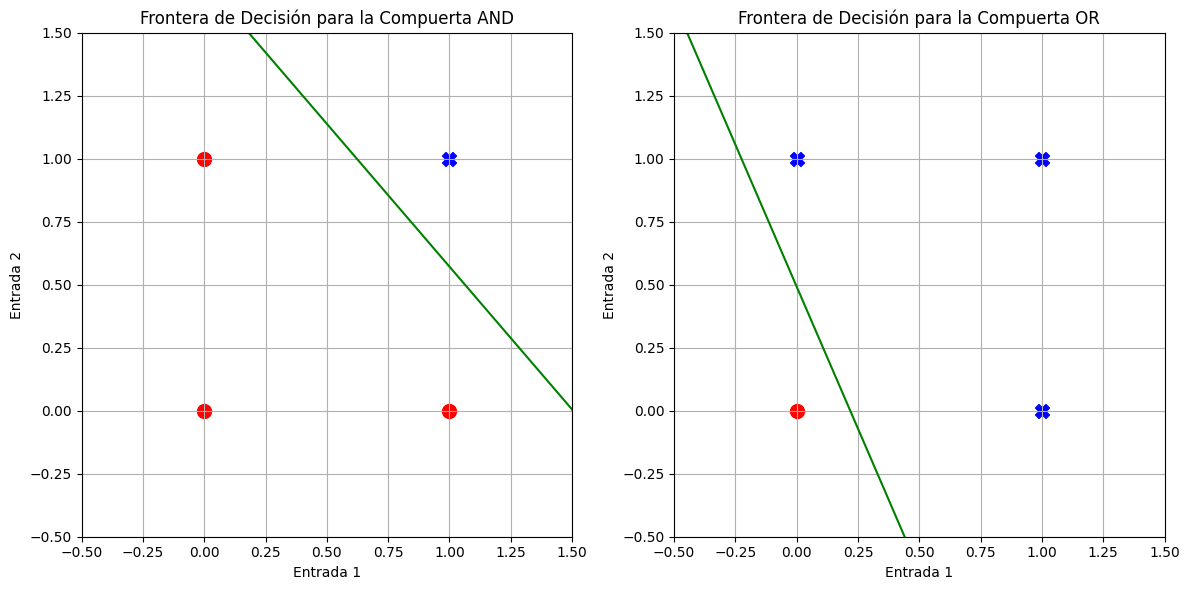

In [3]:
# 2. Instanciar y entrenar el perceptrón
# num_inputs = 2 (x1, x2), num_outputs = 2 (AND, OR)
perceptron = MultiOutputPerceptron(num_inputs=2, num_outputs=2, learning_rate=0.1, epochs=100)
perceptron.train(X, Y)

print("\nPesos aprendidos para la compuerta AND (salida 0):", perceptron.weights[:, 0])
print("Pesos aprendidos para la compuerta OR (salida 1):", perceptron.weights[:, 1])

# 3. Visualizar las fronteras de decisión
plt.figure(figsize=(12, 6))

# Gráfico para la compuerta AND
plt.subplot(1, 2, 1)
plt.title('Frontera de Decisión para la Compuerta AND')
plt.xlabel('Entrada 1')
plt.ylabel('Entrada 2')
plt.xlim([-0.5, 1.5])
plt.ylim([-0.5, 1.5])
plt.grid(True)

# Graficar puntos de datos para AND
# Los puntos 'o' son para salida 0, 'X' para salida 1
# Rojo para 0, Azul para 1
for i in range(X.shape[0]):
    marker = 'o' if Y[i, 0] == 0 else 'X'
    color = 'red' if Y[i, 0] == 0 else 'blue'
    plt.scatter(X[i, 1], X[i, 2], marker=marker, color=color, s=100, label=f'Target {Y[i, 0]}')

# Graficar la frontera de decisión para AND
boundary_params_and = perceptron.get_decision_boundary_params(0)
if boundary_params_and:
    if boundary_params_and[0] == 'line':
        slope, intercept = boundary_params_and[1], boundary_params_and[2]
        x1_vals = np.linspace(-0.5, 1.5, 100)
        x2_vals = slope * x1_vals + intercept
        plt.plot(x1_vals, x2_vals, '-g', label='Frontera de Decisión')
    elif boundary_params_and[0] == 'vertical':
        x1_val = boundary_params_and[1]
        plt.axvline(x=x1_val, color='g', linestyle='-', label='Frontera de Decisión')

# Gráfico para la compuerta OR
plt.subplot(1, 2, 2)
plt.title('Frontera de Decisión para la Compuerta OR')
plt.xlabel('Entrada 1')
plt.ylabel('Entrada 2')
plt.xlim([-0.5, 1.5])
plt.ylim([-0.5, 1.5])
plt.grid(True)

# Graficar puntos de datos para OR
for i in range(X.shape[0]):
    marker = 'o' if Y[i, 1] == 0 else 'X'
    color = 'red' if Y[i, 1] == 0 else 'blue'
    plt.scatter(X[i, 1], X[i, 2], marker=marker, color=color, s=100, label=f'Target {Y[i, 1]}')

# Graficar la frontera de decisión para OR
boundary_params_or = perceptron.get_decision_boundary_params(1)
if boundary_params_or:
    if boundary_params_or[0] == 'line':
        slope, intercept = boundary_params_or[1], boundary_params_or[2]
        x1_vals = np.linspace(-0.5, 1.5, 100)
        x2_vals = slope * x1_vals + intercept
        plt.plot(x1_vals, x2_vals, '-g', label='Frontera de Decisión')
    elif boundary_params_or[0] == 'vertical':
        x1_val = boundary_params_or[1]
        plt.axvline(x=x1_val, color='g', linestyle='-', label='Frontera de Decisión')

plt.tight_layout()
plt.show()

### Visualización del Error de Entrenamiento por Época

Este gráfico muestra cómo el error total del perceptrón disminuye con cada época de entrenamiento. Una rápida caída a cero indica que el modelo aprendió rápidamente a clasificar correctamente todas las muestras de entrenamiento para ambas compuertas lógicas.

El modelo ha convergido en la época 5/100
Entrenamiento finalizado después de 5 épocas.


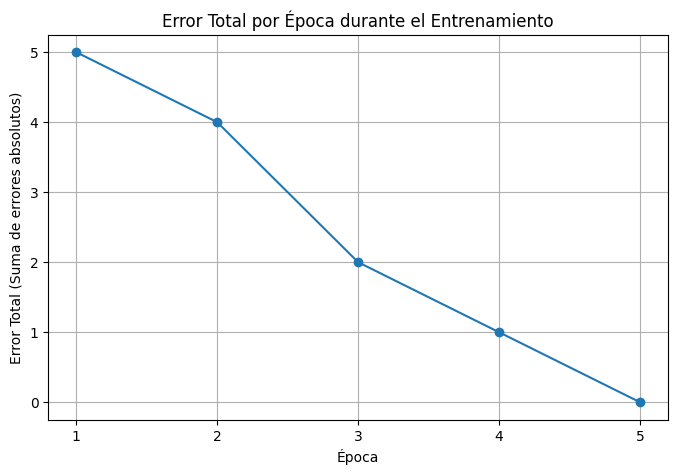

El error converge a cero, indicando que el modelo aprendió las compuertas lógicas.


In [6]:
# 2. Instanciar y entrenar el perceptrón de nuevo para registrar los errores
# num_inputs = 2 (x1, x2), num_outputs = 2 (AND, OR)
perceptron_error_plot = MultiOutputPerceptron(num_inputs=2, num_outputs=2, learning_rate=0.1, epochs=100)
perceptron_error_plot.train(X, Y)

# Graficar el error por época
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(perceptron_error_plot.errors_per_epoch) + 1), perceptron_error_plot.errors_per_epoch, marker='o')
plt.title('Error Total por Época durante el Entrenamiento')
plt.xlabel('Época')
plt.ylabel('Error Total (Suma de errores absolutos)')
plt.grid(True)
plt.xticks(range(1, len(perceptron_error_plot.errors_per_epoch) + 1))
plt.show()

print("El error converge a cero, indicando que el modelo aprendió las compuertas lógicas.")

### Extensión a 3 Entradas: Compuertas Lógicas AND y OR

Ahora, adaptaremos el perceptrón para manejar 3 entradas. Esto implica un nuevo conjunto de datos con una dimensión adicional para las compuertas AND y OR, y el perceptrón aprenderá a separar los puntos mediante un **plano de decisión** en un espacio tridimensional.

In [7]:
# 1. Definir los datasets para las compuertas AND y OR de 3 entradas
# Inputs (X) - Se añade un término de 'bias' (x0=1) y ahora 3 entradas (x1, x2, x3).
X_3_inputs = np.array([
    [1, 0, 0, 0],  # bias, entrada1, entrada2, entrada3
    [1, 0, 0, 1],
    [1, 0, 1, 0],
    [1, 0, 1, 1],
    [1, 1, 0, 0],
    [1, 1, 0, 1],
    [1, 1, 1, 0],
    [1, 1, 1, 1]
])

# Targets (Y)
# Columna 0: Salida de la compuerta AND de 3 entradas
# Columna 1: Salida de la compuerta OR de 3 entradas
y_and_3_inputs = np.array([0, 0, 0, 0, 0, 0, 0, 1])
y_or_3_inputs = np.array([0, 1, 1, 1, 1, 1, 1, 1])
Y_3_inputs = np.column_stack((y_and_3_inputs, y_or_3_inputs))

print("Datos de entrada (X_3_inputs, con bias):\n", X_3_inputs)
print("Datos de salida (Y_3_inputs, [AND, OR]):\n", Y_3_inputs)

Datos de entrada (X_3_inputs, con bias):
 [[1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]
Datos de salida (Y_3_inputs, [AND, OR]):
 [[0 0]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [1 1]]


### Entrenamiento del Perceptrón con 3 Entradas

Instanciamos y entrenamos un nuevo perceptrón, esta vez configurado para aceptar 3 entradas (`num_inputs=3`), manteniendo las 2 salidas para AND y OR. La lógica de entrenamiento sigue siendo la misma.

In [8]:
# 2. Instanciar y entrenar el perceptrón con 3 entradas
# num_inputs = 3 (x1, x2, x3), num_outputs = 2 (AND, OR)
perceptron_3_inputs = MultiOutputPerceptron(num_inputs=3, num_outputs=2, learning_rate=0.1, epochs=100)
perceptron_3_inputs.train(X_3_inputs, Y_3_inputs)

print("\nPesos aprendidos para la compuerta AND de 3 entradas (salida 0):", perceptron_3_inputs.weights[:, 0])
print("Pesos aprendidos para la compuerta OR de 3 entradas (salida 1):", perceptron_3_inputs.weights[:, 1])

El modelo ha convergido en la época 10/100
Entrenamiento finalizado después de 10 épocas.

Pesos aprendidos para la compuerta AND de 3 entradas (salida 0): [-0.46410658  0.28162824  0.11409642  0.1642468 ]
Pesos aprendidos para la compuerta OR de 3 entradas (salida 1): [-0.08626121  0.14328294  0.12561837  0.12167743]


### Visualización de Puntos en 3D para 3 Entradas

Dado que ahora tenemos 3 entradas, la frontera de decisión es un plano en el espacio 3D. Aquí visualizaremos los puntos de entrada para cada compuerta (AND y OR) en un gráfico 3D, coloreados según su salida esperada. Esto ayuda a entender cómo el perceptrón clasifica en este espacio. La línea verde que graficábamos antes en 2D, ahora sería un plano.

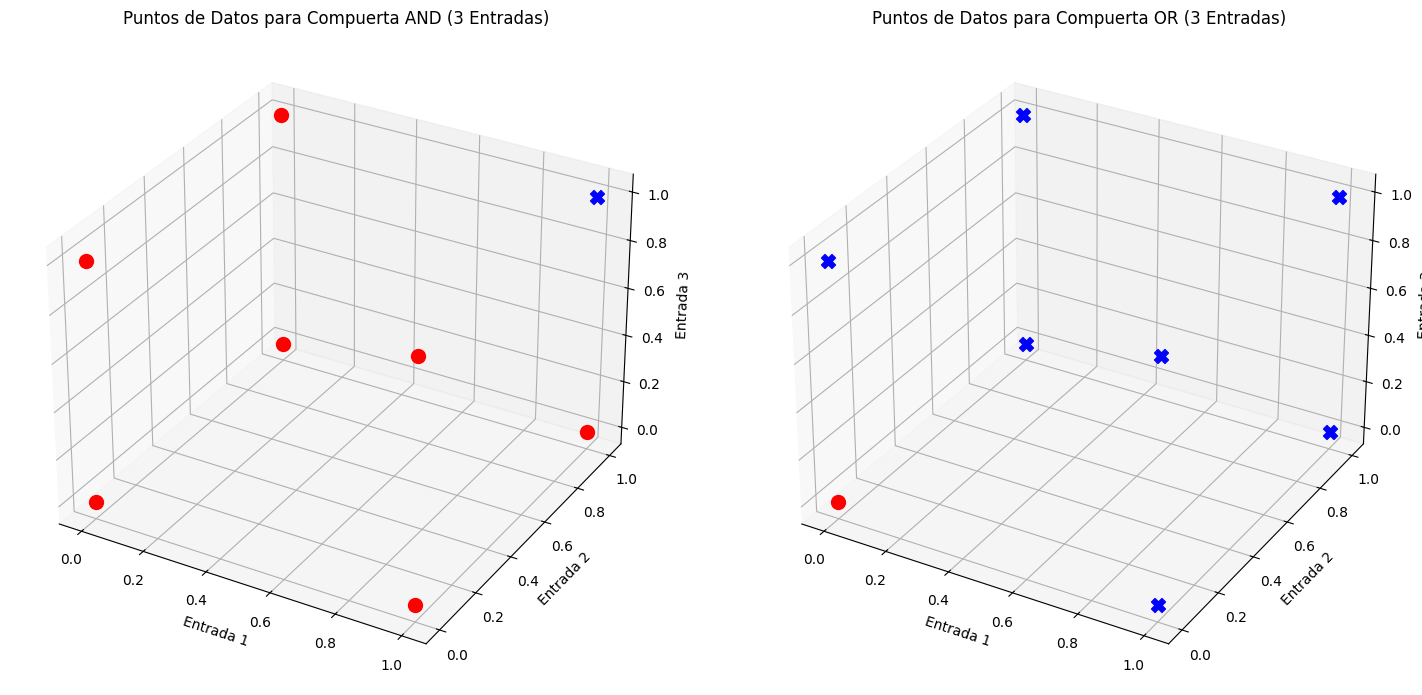

In [9]:
from mpl_toolkits.mplot3d import Axes3D

plt.figure(figsize=(15, 7))

# Gráfico 3D para la compuerta AND de 3 entradas
ax_and = plt.subplot(121, projection='3d')
ax_and.set_title('Puntos de Datos para Compuerta AND (3 Entradas)')
ax_and.set_xlabel('Entrada 1')
ax_and.set_ylabel('Entrada 2')
ax_and.set_zlabel('Entrada 3')

for i in range(X_3_inputs.shape[0]):
    x1, x2, x3 = X_3_inputs[i, 1], X_3_inputs[i, 2], X_3_inputs[i, 3]
    target = Y_3_inputs[i, 0]
    color = 'red' if target == 0 else 'blue'
    marker = 'o' if target == 0 else 'X'
    ax_and.scatter(x1, x2, x3, color=color, marker=marker, s=100)

# Gráfico 3D para la compuerta OR de 3 entradas
ax_or = plt.subplot(122, projection='3d')
ax_or.set_title('Puntos de Datos para Compuerta OR (3 Entradas)')
ax_or.set_xlabel('Entrada 1')
ax_or.set_ylabel('Entrada 2')
ax_or.set_zlabel('Entrada 3')

for i in range(X_3_inputs.shape[0]):
    x1, x2, x3 = X_3_inputs[i, 1], X_3_inputs[i, 2], X_3_inputs[i, 3]
    target = Y_3_inputs[i, 1]
    color = 'red' if target == 0 else 'blue'
    marker = 'o' if target == 0 else 'X'
    ax_or.scatter(x1, x2, x3, color=color, marker=marker, s=100)

plt.tight_layout()
plt.show()

### Visualización del Plano de Decisión en 3D para 3 Entradas

Aquí visualizaremos los puntos de datos y el plano de decisión aprendido por el perceptrón para las compuertas AND y OR de 3 entradas. El plano representa la frontera que el modelo utiliza para separar las clases (salida 0 y salida 1).

El modelo ha convergido en la época 16/100
Entrenamiento finalizado después de 16 épocas.


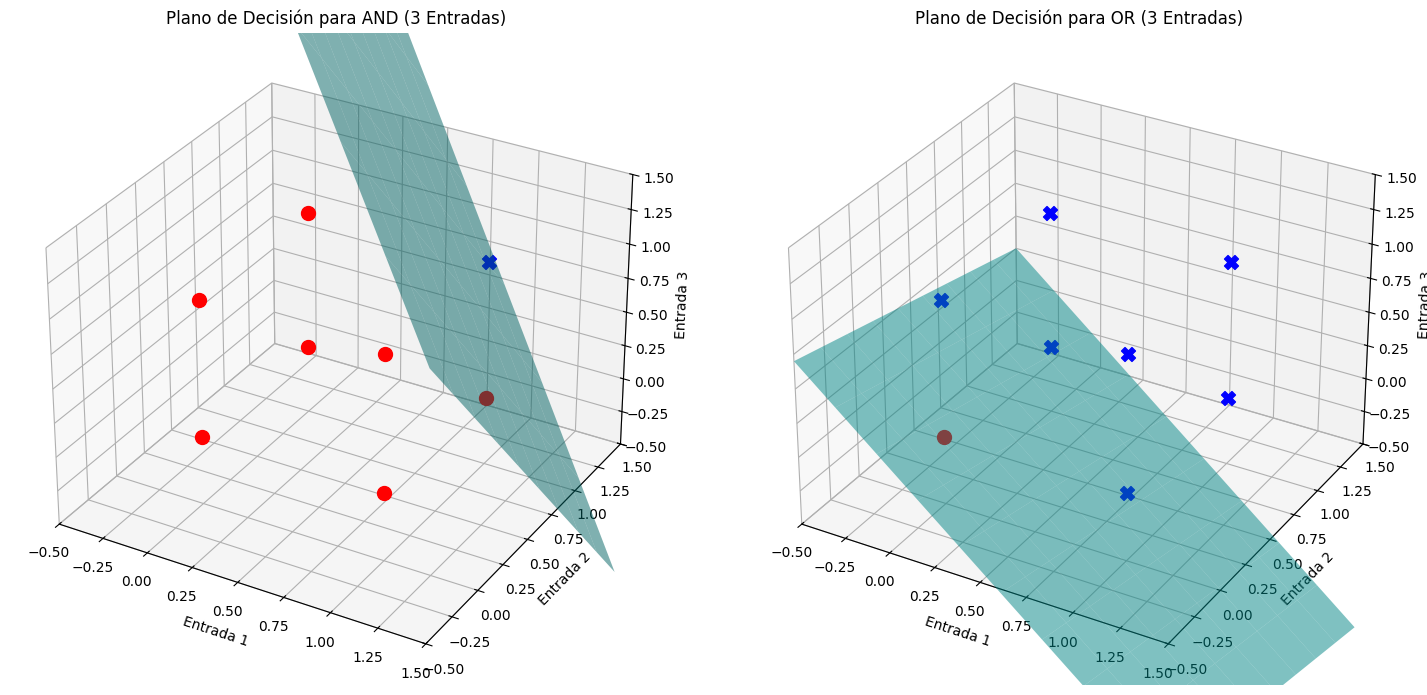

In [12]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np

# Re-entrenar el perceptrón con 3 entradas para usar la clase actualizada
# (Esto se hace para asegurar que el método get_weights_for_output esté disponible)
perceptron_3_inputs_plot = MultiOutputPerceptron(num_inputs=3, num_outputs=2, learning_rate=0.1, epochs=100)
perceptron_3_inputs_plot.train(X_3_inputs, Y_3_inputs)

# Función para graficar el plano de decisión
def plot_decision_plane(ax, weights, title):
    # La ecuación del plano es w0 + w1*x1 + w2*x2 + w3*x3 = 0
    # donde w = [w0, w1, w2, w3]
    # Entonces, x3 = (-w0 - w1*x1 - w2*x2) / w3

    # Crear una malla de puntos para x1 y x2
    x1_min, x1_max = -0.5, 1.5
    x2_min, x2_max = -0.5, 1.5
    x1_vals = np.linspace(x1_min, x1_max, 10)
    x2_vals = np.linspace(x2_min, x2_max, 10)
    X1, X2 = np.meshgrid(x1_vals, x2_vals)

    # Calcular X3 (z) para el plano de decisión
    # Asegurarse de que w[3] no sea cero para evitar división por cero
    if weights[3] != 0:
        X3 = (-weights[0] - weights[1] * X1 - weights[2] * X2) / weights[3]
        ax.plot_surface(X1, X2, X3, alpha=0.5, color='cyan')
    else:
        # Caso especial si w3 es 0 (plano paralelo al eje x3)
        # Esto significaría que la decisión no depende de x3
        # Podríamos dibujar una línea o no dibujar nada, dependiendo del contexto.
        # Por simplicidad, no dibujaremos si w3 es 0, asumiendo que es una configuración rara
        print(f"Advertencia: w3 es cero para {title}, no se puede dibujar el plano de forma estándar.")

    ax.set_title(title)
    ax.set_xlabel('Entrada 1')
    ax.set_ylabel('Entrada 2')
    ax.set_zlabel('Entrada 3')
    ax.set_xlim(x1_min, x1_max)
    ax.set_ylim(x2_min, x2_max)
    ax.set_zlim(x1_min, x1_max) # Usar mismos límites para z para consistencia


plt.figure(figsize=(15, 7))

# Gráfico 3D para la compuerta AND de 3 entradas con plano de decisión
ax_and_plane = plt.subplot(121, projection='3d')
for i in range(X_3_inputs.shape[0]):
    x1, x2, x3 = X_3_inputs[i, 1], X_3_inputs[i, 2], X_3_inputs[i, 3]
    target = Y_3_inputs[i, 0]
    color = 'red' if target == 0 else 'blue'
    marker = 'o' if target == 0 else 'X'
    ax_and_plane.scatter(x1, x2, x3, color=color, marker=marker, s=100)

weights_and = perceptron_3_inputs_plot.get_weights_for_output(0)
plot_decision_plane(ax_and_plane, weights_and, 'Plano de Decisión para AND (3 Entradas)')

# Gráfico 3D para la compuerta OR de 3 entradas con plano de decisión
ax_or_plane = plt.subplot(122, projection='3d')
for i in range(X_3_inputs.shape[0]):
    x1, x2, x3 = X_3_inputs[i, 1], X_3_inputs[i, 2], X_3_inputs[i, 3]
    target = Y_3_inputs[i, 1]
    color = 'red' if target == 0 else 'blue'
    marker = 'o' if target == 0 else 'X'
    ax_or_plane.scatter(x1, x2, x3, color=color, marker=marker, s=100)

weights_or = perceptron_3_inputs_plot.get_weights_for_output(1)
plot_decision_plane(ax_or_plane, weights_or, 'Plano de Decisión para OR (3 Entradas)')

plt.tight_layout()
plt.show()